In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [13]:
from google.colab import files

uploaded = files.upload()

Saving student_academic_performance.csv to student_academic_performance.csv


In [14]:
import pandas as pd

df = pd.read_csv("student_academic_performance.csv")   # Replace with your actual file name

In [15]:
import os

print(os.listdir())

['.config', 'student_academic_performance.csv', 'student-grade.xls', 'student-grade.csv', 'sample_data']


In [16]:
df.columns = df.columns.str.strip()

In [17]:
print("First 5 Rows")
print(df.head())

print("\nShape")
print(df.shape)

print("\nColumns")
print(df.columns)

print("\nInformation")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

print("\nStatistical Summary")
print(df.describe())

First 5 Rows
   student_id  gender department  semester  internal_marks  external_marks  \
0           1    Male        CSE         1              15              36   
1           2  Female         IT         2              13              32   
2           3    Male        ECE         3              13              55   
3           4  Female         ME         4              15              49   
4           5    Male         CE         5              29              45   

   total_marks  percentage  cgpa grade result  
0           51          51   5.1     C   Pass  
1           45          45   4.5     C   Pass  
2           68          68   6.8     B   Pass  
3           64          64   6.4     B   Pass  
4           74          74   7.4    B+   Pass  

Shape
(199, 11)

Columns
Index(['student_id', 'gender', 'department', 'semester', 'internal_marks',
       'external_marks', 'total_marks', 'percentage', 'cgpa', 'grade',
       'result'],
      dtype='object')

Information
<clas

In [19]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder()

df[['gender', 'department', 'grade', 'result']] = encoder.fit_transform(
    df[['gender', 'department', 'grade', 'result']]
)

In [20]:
label = "cgpa"

print("Target Variable:", label)

Target Variable: cgpa


In [21]:
corr = df.corr(numeric_only=True)

print(corr[label].sort_values(ascending=False))

cgpa              1.000000
total_marks       1.000000
percentage        1.000000
external_marks    0.913058
internal_marks    0.479662
result            0.358311
student_id        0.083065
semester          0.083065
department        0.055984
gender            0.042210
grade            -0.797790
Name: cgpa, dtype: float64


In [22]:
threshold = 0.30

relevant_features = corr[label][abs(corr[label]) >= threshold]

print(relevant_features)

features = relevant_features.index.tolist()

features.remove(label)

print("\nSelected Features")

print(features)

internal_marks    0.479662
external_marks    0.913058
total_marks       1.000000
percentage        1.000000
cgpa              1.000000
grade            -0.797790
result            0.358311
Name: cgpa, dtype: float64

Selected Features
['internal_marks', 'external_marks', 'total_marks', 'percentage', 'grade', 'result']


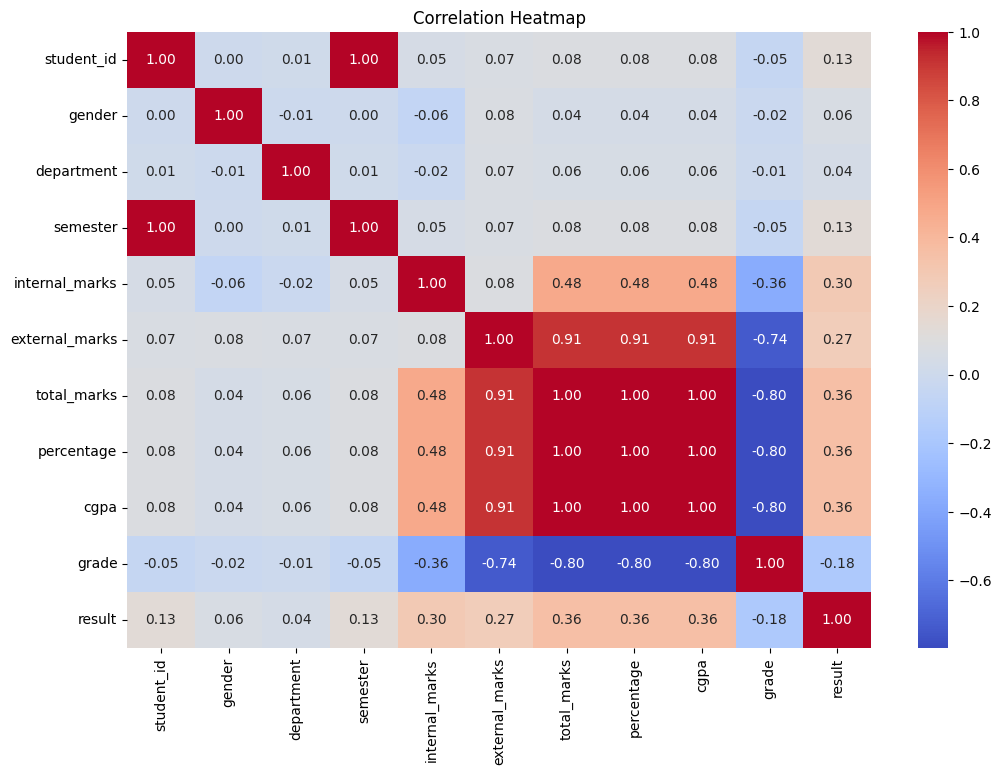

In [23]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

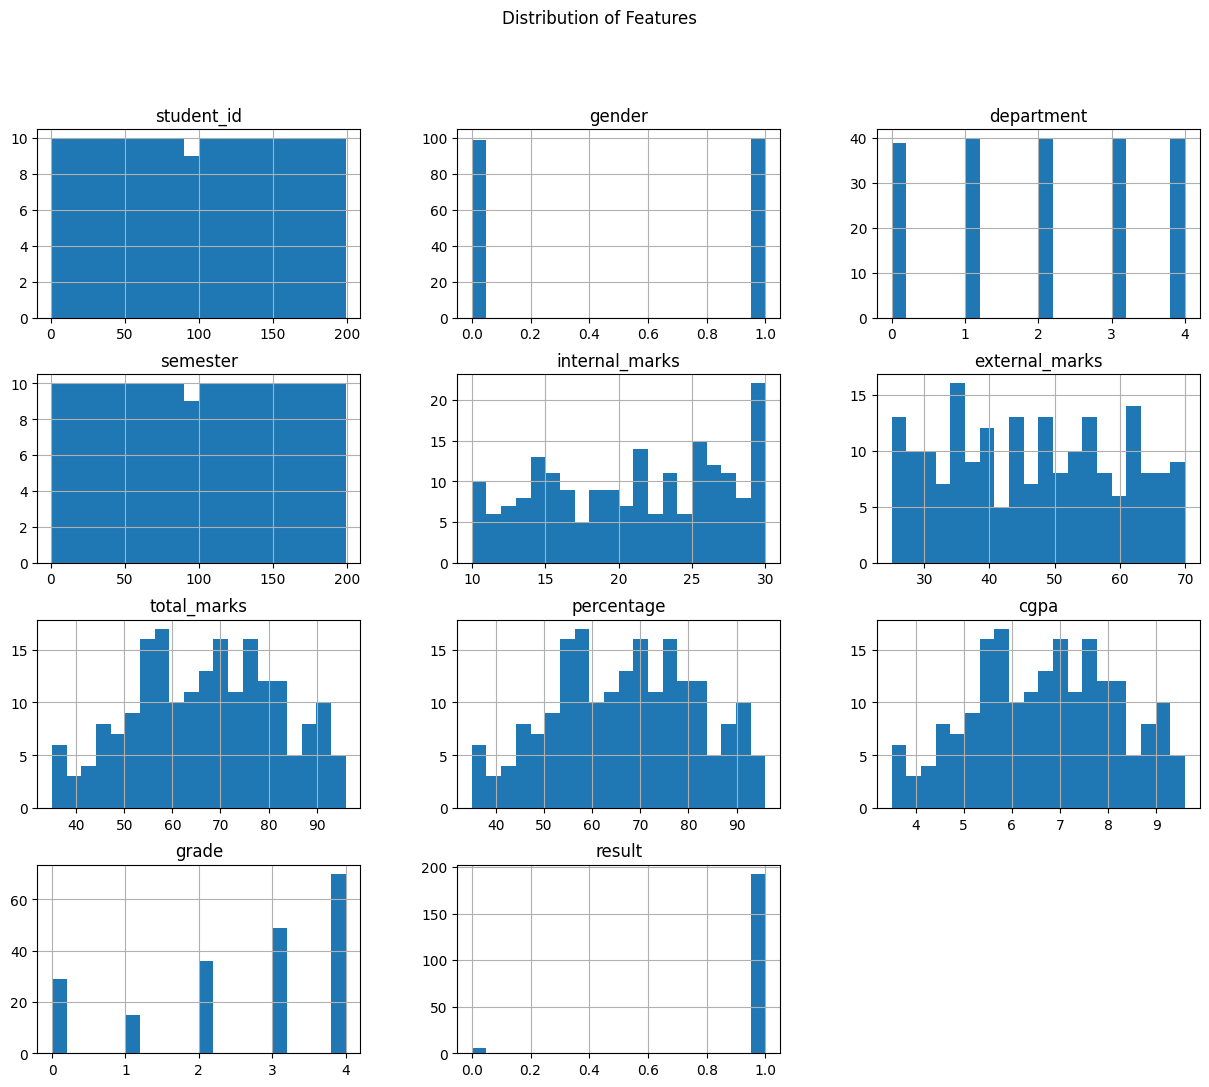

In [24]:
df.hist(figsize=(15,12), bins=20)

plt.suptitle("Distribution of Features")

plt.show()

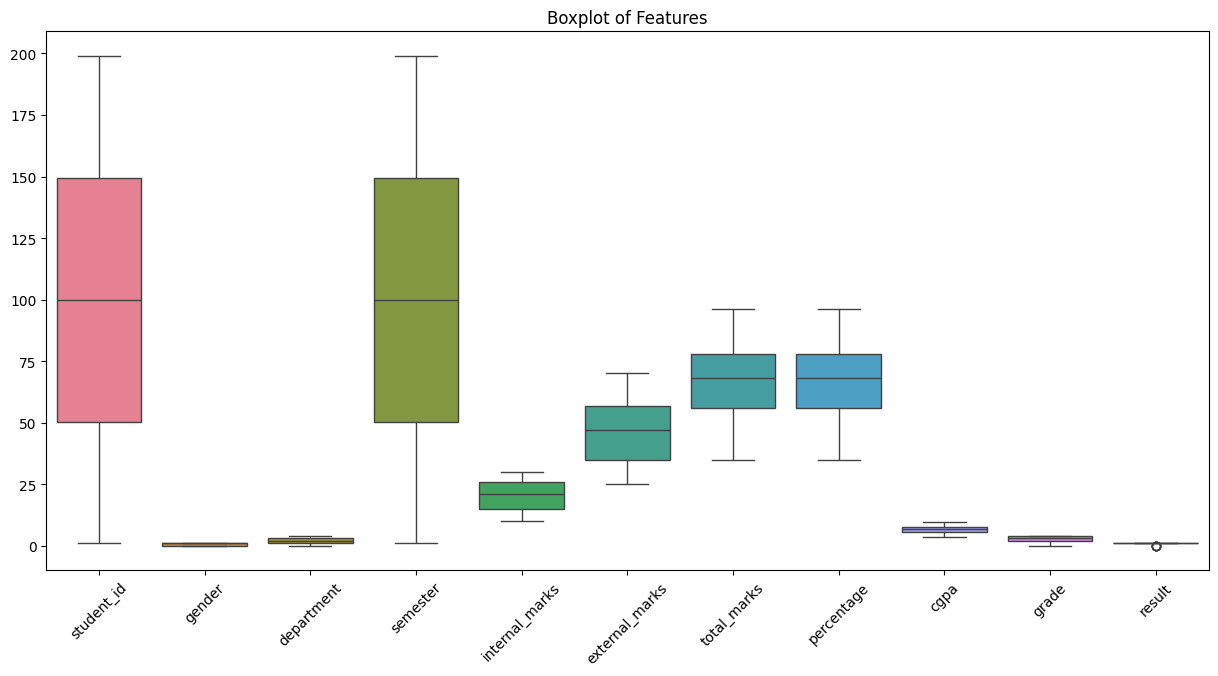

In [25]:
plt.figure(figsize=(15,7))

sns.boxplot(data=df)

plt.xticks(rotation=45)

plt.title("Boxplot of Features")

plt.show()

In [26]:
best_feature = corr[label].drop(label).abs().idxmax()

print("Best Feature:", best_feature)

X = df[[best_feature]]

y = df[label]

Best Feature: total_marks


Simple Linear Regression
Coefficient: 0.09999999999999999
Intercept: 8.881784197001252e-16
MAE: 4.884981308350689e-16
MSE: 5.9164567891575885e-31
RMSE: 7.691850745534255e-16
R2 Score: 1.0


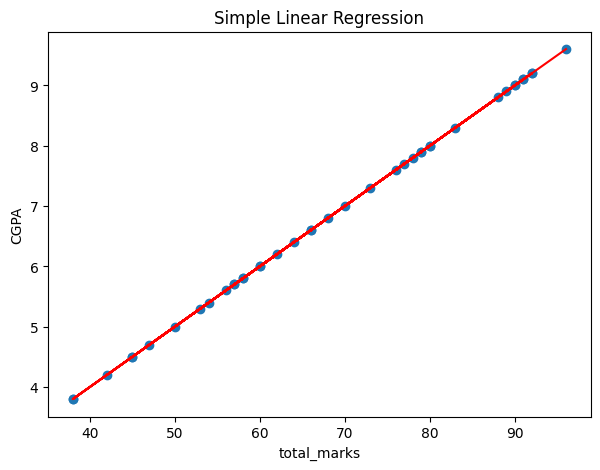

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
model = LinearRegression()

model.fit(X_train, y_train)

prediction = model.predict(X_test)
print("Simple Linear Regression")

print("Coefficient:", model.coef_[0])

print("Intercept:", model.intercept_)

print("MAE:", mean_absolute_error(y_test, prediction))

print("MSE:", mean_squared_error(y_test, prediction))

print("RMSE:", np.sqrt(mean_squared_error(y_test, prediction)))

print("R2 Score:", r2_score(y_test, prediction))

plt.figure(figsize=(7,5))

plt.scatter(X_test, y_test)

plt.plot(X_test, prediction, color="red")

plt.xlabel(best_feature)

plt.ylabel("CGPA")

plt.title("Simple Linear Regression")

plt.show()


In [28]:
X = df[features]

y = df[label]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

multi_model = LinearRegression()

multi_model.fit(X_train, y_train)

prediction = multi_model.predict(X_test)

print("Multiple Linear Regression")

print("Intercept:", multi_model.intercept_)

print("\nCoefficients")

for feature, coef in zip(features, multi_model.coef_):
    print(feature, ":", coef)

print("\nMAE:", mean_absolute_error(y_test, prediction))

print("MSE:", mean_squared_error(y_test, prediction))

print("RMSE:", np.sqrt(mean_squared_error(y_test, prediction)))

print("R2 Score:", r2_score(y_test, prediction))

Multiple Linear Regression
Intercept: -8.881784197001252e-16

Coefficients
internal_marks : 0.019999999999999962
external_marks : 0.02000000000000003
total_marks : 0.04000000000000001
percentage : 0.04000000000000001
grade : -3.903127820947816e-18
result : -2.553296116203363e-17

MAE: 1.1102230246251565e-15
MSE: 2.406025760924086e-30
RMSE: 1.5511369252661372e-15
R2 Score: 1.0


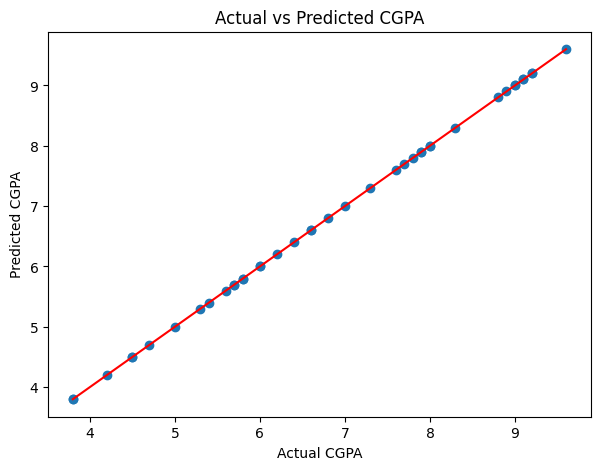

In [29]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, prediction)

plt.xlabel("Actual CGPA")

plt.ylabel("Predicted CGPA")

plt.title("Actual vs Predicted CGPA")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.show()